### Implement PageRank Algorithm

In [24]:
# Install the required libraries
%pip install requests beautifulsoup4 matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
# Import the required libraries
import requests
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from urllib.parse import urljoin,urlparse,urldefrag

In [26]:
# Crawl web pages using BS4
start_url = "https://en.wikipedia.org/wiki/Machine_learning"
MAX_PAGES = 10

session = requests.Session()
session.headers.update({
    'User-Agent':'EducationalPageRankDemo/1.0'
})

def normalise_url(url):
    url = urldefrag(url)[0]  # Remove fragment
    parsed_url = urlparse(url)
    if parsed_url.netloc.lower() not in ['en.wikipedia.org', 'www.en.wikipedia.org']:
        return None
    if not parsed_url.path.startswith('/wiki/'):
        return None
    if ":" in parsed_url.path[len("/wiki/"):]:  # Exclude special pages
        return None
    
    return "https://en.wikipedia.org" + parsed_url.path
    


queue = [normalise_url(start_url)]
visited = set()
page_titles = {}
extracted_links = {}

while queue and len(visited) < MAX_PAGES:
    url = queue.pop(0)
    if url in visited:
        continue

    try:
        response = session.get(url,timeout=15)
        response.raise_for_status()
        soup = BeautifulSoup(response.text, 'html.parser')

        title_tag=soup.find("title")
        title = title_tag.get_text(strip=True) if title_tag else url

        links = set()

        for tag in soup.find_all('a',href=True):
            full_url = urljoin(url, tag['href'])
            clean_url = normalise_url(full_url)

            if clean_url:
                links.add(clean_url)

        visited.add(url)
        page_titles[url] = title
        extracted_links[url] = links
        for link in sorted(links):
            if link not in visited and link not in queue:
                queue.append(link)
        print("Collected:",title)
    except Exception as e:
        print("Could not fetch:",url,"Error:",e)

print("Total pages collected:",len(visited))

Collected: Machine learning - Wikipedia
Collected: 15.ai - Wikipedia
Collected: 2008 financial crisis - Wikipedia
Collected: AAAI Conference on Artificial Intelligence - Wikipedia
Collected: ACM Computing Classification System - Wikipedia
Collected: ACM Computing Surveys - Wikipedia
Collected: ACT-R - Wikipedia
Collected: ADALINE - Wikipedia
Collected: AI-assisted software development - Wikipedia
Collected: AI-generated violent extremist content - Wikipedia
Total pages collected: 10


In [27]:
# Build the direceted graph
pages = list(visited)
web_graph = {
    page :[
        link for link in extracted_links[page]
        if link in visited
    ]
    for page in pages
}

print("Webgraph:\n")
for page, links in web_graph.items():
    print(page_titles[page])
    print("Links to:",[page_titles[link] for link in links])
    print()

Webgraph:

15.ai - Wikipedia
Links to: ['Machine learning - Wikipedia', 'ACT-R - Wikipedia', '15.ai - Wikipedia']

ACT-R - Wikipedia
Links to: ['Machine learning - Wikipedia', 'ACT-R - Wikipedia', '15.ai - Wikipedia']

ACM Computing Surveys - Wikipedia
Links to: ['ACM Computing Surveys - Wikipedia']

AI-assisted software development - Wikipedia
Links to: ['Machine learning - Wikipedia', 'AI-assisted software development - Wikipedia', 'AI-generated violent extremist content - Wikipedia']

2008 financial crisis - Wikipedia
Links to: ['2008 financial crisis - Wikipedia']

AAAI Conference on Artificial Intelligence - Wikipedia
Links to: ['AAAI Conference on Artificial Intelligence - Wikipedia', 'Machine learning - Wikipedia']

ADALINE - Wikipedia
Links to: ['ADALINE - Wikipedia']

ACM Computing Classification System - Wikipedia
Links to: ['Machine learning - Wikipedia', 'ACM Computing Classification System - Wikipedia']

AI-generated violent extremist content - Wikipedia
Links to: ['AI-gen

In [28]:
# Initalize PageRank values
N = len(pages)
damping_factor = 0.85
max_iterations = 100
tolerance = 1.e-8

if N==0:
    raise ValueError("No pages collected. Cannot compute PageRank.")


pagerank = {page: 1.0 / N for page in pages}
print("Number of pages:",N)
print("Damping factor:",damping_factor)
print("Initial PageRank values:",pagerank)

Number of pages: 10
Damping factor: 0.85
Initial PageRank values: {'https://en.wikipedia.org/wiki/15.ai': 0.1, 'https://en.wikipedia.org/wiki/ACT-R': 0.1, 'https://en.wikipedia.org/wiki/ACM_Computing_Surveys': 0.1, 'https://en.wikipedia.org/wiki/AI-assisted_software_development': 0.1, 'https://en.wikipedia.org/wiki/2008_financial_crisis': 0.1, 'https://en.wikipedia.org/wiki/AAAI_Conference_on_Artificial_Intelligence': 0.1, 'https://en.wikipedia.org/wiki/ADALINE': 0.1, 'https://en.wikipedia.org/wiki/ACM_Computing_Classification_System': 0.1, 'https://en.wikipedia.org/wiki/AI-generated_violent_extremist_content': 0.1, 'https://en.wikipedia.org/wiki/Machine_learning': 0.1}


In [29]:
# Implement the PageRank algorithm
for iteration in range(max_iterations):
    new_pagerank ={
        page:(1-damping_factor)/N
        for page in pages
    }
    # Handling page with no outgoing links
    dangling_sum = sum(
        pagerank[page]
        for page in pages
        if len(web_graph[page])==0
    )

    for page in pages:
        new_pagerank[page] +=(
            damping_factor * dangling_sum / N
        )

    for source in pages:
        outgoing = web_graph[source]

        if outgoing:
            contribution = (
                damping_factor * pagerank[source] / len(outgoing)
            )
            for target in outgoing:
                new_pagerank[target] += contribution
    diff = sum(abs(new_pagerank[page]-pagerank[page]) for page in pages)
    pagerank = new_pagerank
    if diff < tolerance:
        break

print("Iterations completed:",iteration+1)
print("Page rank calculated successfully.")

Iterations completed: 64
Page rank calculated successfully.


In [30]:
# Display the final ranking 
ranked_pages = sorted(
    pagerank.items(),
    key=lambda x: x[1],
    reverse=True
)

print("Final PageRank Ranking:\n")
for rank, (page, score) in enumerate(ranked_pages, start=1):
    print(f"{rank}. {page_titles[page]} - PageRank: {score:.6f}")

Final PageRank Ranking:

1. ACM Computing Surveys - Wikipedia - PageRank: 0.176354
2. 2008 financial crisis - Wikipedia - PageRank: 0.176354
3. ADALINE - Wikipedia - PageRank: 0.176354
4. Machine learning - Wikipedia - PageRank: 0.134743
5. 15.ai - Wikipedia - PageRank: 0.061046
6. ACT-R - Wikipedia - PageRank: 0.061046
7. AI-assisted software development - Wikipedia - PageRank: 0.061046
8. AI-generated violent extremist content - Wikipedia - PageRank: 0.061046
9. AAAI Conference on Artificial Intelligence - Wikipedia - PageRank: 0.046005
10. ACM Computing Classification System - Wikipedia - PageRank: 0.046005


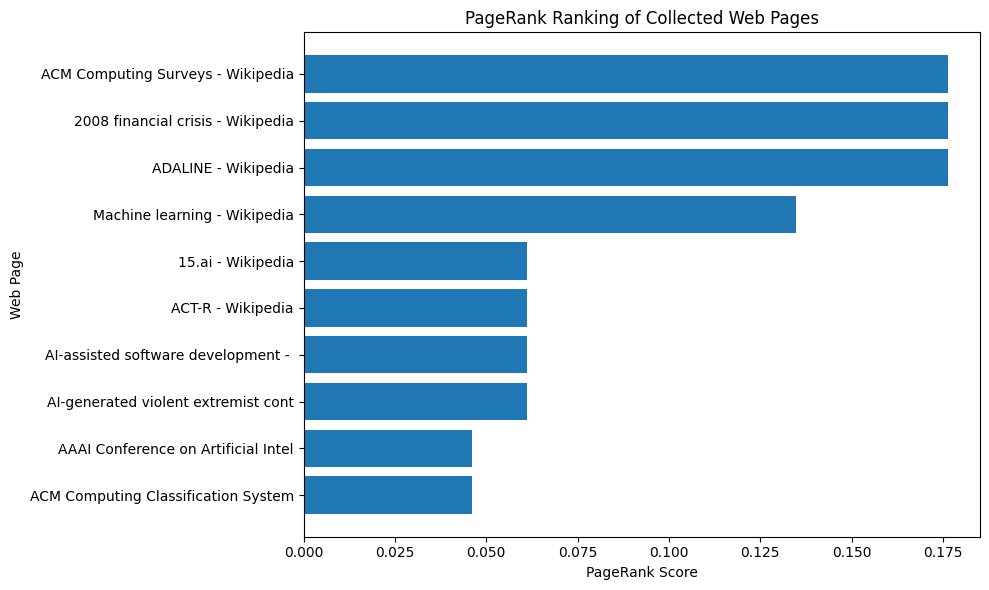

In [31]:
# Visualize the Pagerank scores
top_pages = ranked_pages[:10]

labels = [
    page_titles[page][:35]
    for page, score in top_pages
]

scores = [score for page, score in top_pages]

plt.figure(figsize=(10, 6))
plt.barh(labels[::-1], scores[::-1])
plt.xlabel("PageRank Score")
plt.ylabel("Web Page")
plt.title("PageRank Ranking of Collected Web Pages")
plt.tight_layout()
plt.show()